<a href="https://colab.research.google.com/github/siddikmulla980-ui/data-analyst-job-market-analysis/blob/main/notebooks/job_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# 1. Data Load Karo
df_jobs = pd.read_csv('clean_jobs.csv')

print("✅ Data Successfully Loaded!")
print(f"Total Jobs: {df_jobs.shape[0]}")
print("-" * 40)

# 2. Top Skills Nikaalo (Title aur Company ke basis par)
# Kyunki isme description nahi hai, hum title aur company ke words check karenge
skills_list = ['python', 'sql', 'excel', 'tableau', 'power bi', 'pandas', 'numpy', 'aws', 'azure', 'spark', 'machine learning', 'data analyst', 'data scientist', 'engineer']

# Title aur company ko jod kar ek text banate hain
all_text = ' '.join(df_jobs['title'].dropna().astype(str)).lower() + ' ' + ' '.join(df_jobs['company'].dropna().astype(str)).lower()

skill_counts = {}
for skill in skills_list:
    count = len(re.findall(r'\b' + re.escape(skill) + r'\b', all_text))
    skill_counts[skill] = count

sorted_skills = dict(sorted(skill_counts.items(), key=lambda item: item[1], reverse=True))

print("🔥 Top Skills/Keywords in Demand:")
for skill, count in sorted_skills.items():
    if count > 0:
        print(f"  {skill.title()}: {count} mentions")

# 3. Top Companies
print("\n🏢 Top 10 Hiring Companies:")
print(df_jobs['company'].value_counts().head(10))

# 4. Top Locations
print("\n📍 Top 10 Hiring Locations:")
print(df_jobs['location'].value_counts().head(10))

✅ Data Successfully Loaded!
Total Jobs: 1048
----------------------------------------
🔥 Top Skills/Keywords in Demand:
  Engineer: 306 mentions
  Data Analyst: 279 mentions
  Data Scientist: 203 mentions
  Machine Learning: 38 mentions
  Python: 16 mentions
  Sql: 13 mentions
  Tableau: 5 mentions
  Aws: 3 mentions
  Azure: 3 mentions
  Power Bi: 2 mentions
  Spark: 1 mentions

🏢 Top 10 Hiring Companies:
company
Meta         70
Netflix      33
Amazon       18
Google       16
****         14
Lensa         9
TikTok        8
********      8
AARATECH      8
Handshake     7
Name: count, dtype: int64

📍 Top 10 Hiring Locations:
location
United States                      73
New York, NY                       65
San Francisco, CA                  49
Bengaluru, Karnataka, India        40
Remote, US                         23
London, England, United Kingdom    15
Seattle, WA                        15
London Area, United Kingdom        14
Los Angeles, CA                    13
Gurugram, Haryana, 

/tmp/ipykernel_538/1832831958.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(top_skills.values()), y=list(top_skills.keys()), palette='magma')


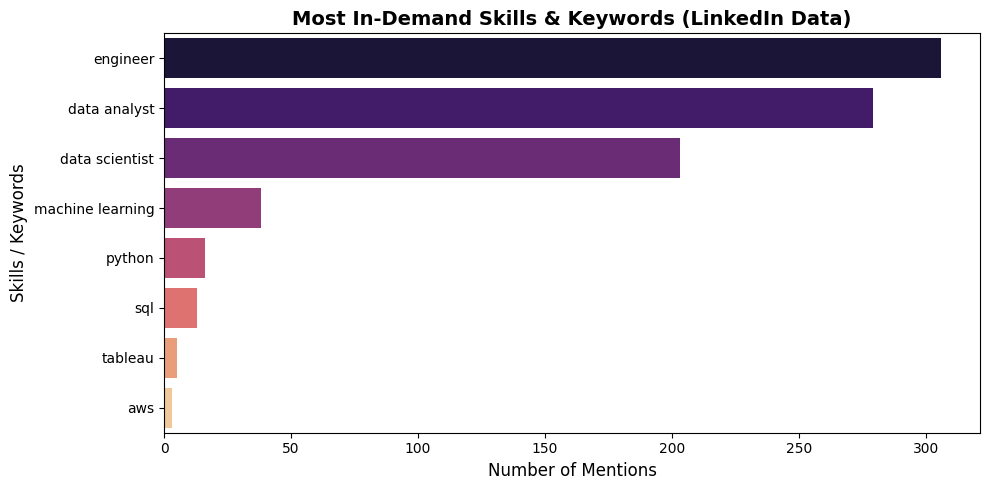

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sirf top 8 skills ko graph mein dikhate hain taaki clean lage
top_skills = dict(list(sorted_skills.items())[:8])

plt.figure(figsize=(10, 5))
sns.barplot(x=list(top_skills.values()), y=list(top_skills.keys()), palette='magma')
plt.title('Most In-Demand Skills & Keywords (LinkedIn Data)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Mentions', fontsize=12)
plt.ylabel('Skills / Keywords', fontsize=12)
plt.tight_layout()
plt.show()